# Unsupervised Learning

## Import

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD


## Preprocess

Le but de cette division nous permet de prendre le CSV initial et d'en normaliser les données afin de pouvoir les faire analyser par l'IA plus efficacement.

On va créer un nouveau CSV avec 3 colonnes : chiffre couleur et phrase(symptome)

Le but va être de séparer les données du CSV inital qui ne possède pas de labals. Pour ceci, on va séparer les données aux virgules.
On enlève les guillemets qui ne sont pas toujours présente pour n'avoir que le symptôme propre sans avoir d'élément parasites.

In [2]:
df = pd.DataFrame(columns=["chiffre", "couleur", "phrase"])

with open("Student_Dataset.csv", "r", encoding="utf-8") as fichier:

    for ligne in fichier:
        ligne = ligne.strip()

        chiffre, phrase = ligne.split(",", 1)

        if "0x000000" in phrase:
            couleur, symptome = phrase.split(",", 1)
            symptome = symptome.replace('"', "")
            df.loc[len(df)] = [chiffre, couleur, symptome]

        else :
            phrase = phrase.replace('"', "")
            df.loc[len(df)] = [chiffre, "", phrase]

df.to_csv("Nouveau_Dataset.csv", index=False)

## Vérification

Pour vérifier que tout à été bien ajouté correctement, on vérifie la longueur des trois colonnes.

Et qu'il n'y est pas de vide dans les colonnes chiffre et phrase

In [3]:
print("Longueur de la colonne chiffre :", len(df["chiffre"]))
print("Longueur de la colonne couleur :", len(df["couleur"]))
print("Longueur de la colonne phrase :", len(df["phrase"]))

for k in df["chiffre"]:
    if k == "" or k == None:
        print("Erreur de valeur")

for k in df["phrase"]:
    if k == "" or k == None:
        print("Erreur de valeur")

Longueur de la colonne chiffre : 1011
Longueur de la colonne couleur : 1011
Longueur de la colonne phrase : 1011


## TF-IDF Vectorizer

Pour pouvoir entrainer notre IA, on va trasformer tous les mots en vecteur, qui seront compréhensible par notre IA.

On obtient également le nombre de mots différents parmi les 1011 lignes composant le dataset.

Pour éviter d'être embetté par des mots non pertinents au problème, on vectorise en enlevant les stop-words(the, a ...) afin de ne garder que des mots relatifs aux symptomes.

In [4]:
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df["phrase"])
noms = vectorizer.get_feature_names_out()
print(X.shape)

(1011, 2135)


## TruncatedSVD

In [ ]:
resultats = []

for n_comp in range(10, 101, 10):
    svd = TruncatedSVD(n_components=n_comp, random_state=42)
    X_reduced = svd.fit_transform(X)

    for k in range(2, 40):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X_reduced)
        score = silhouette_score(X_reduced, kmeans.labels_)
        resultats.append((n_comp, k, score))

df_resultats = pd.DataFrame(resultats, columns=["n_components", "k", "silhouette"])

print(df_resultats)

meilleur = df_resultats.loc[df_resultats["silhouette"].idxmax()]
print("Meilleure combinaison (sans contrainte) :\n", meilleur)

svd_final = TruncatedSVD(n_components=10, random_state=42)
X_reduced_final = svd_final.fit_transform(X)
print("Variance expliquée avec 10 composantes :", svd_final.explained_variance_ratio_.sum())

Variance expliquée avec 10 composantes : 0.3825975258009121


## Elbow Method (Inertias)

Ensuite, nous faisons la "Elbow Method" (Méthode du coude) afin de déterminer une zone de valeurs idéales pour trouver notre nombre de cluster le plus efficace.

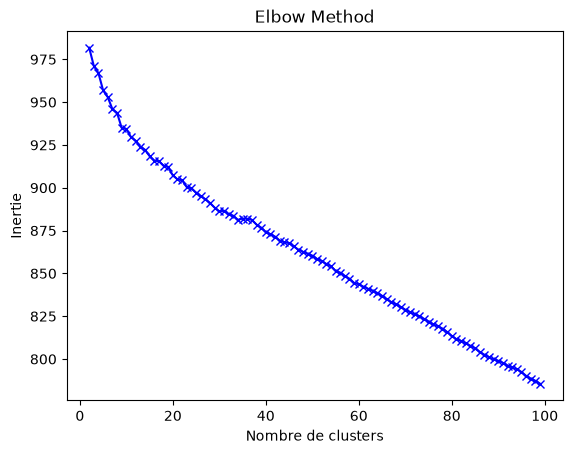

In [ ]:

inertias = []
K = range(2, 100)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    inertias.append(kmeanModel.inertia_)

plt.plot(K, inertias, 'bx-')
plt.xlabel('Nombre de clusters')
plt.ylabel('Inertie')
plt.title("Elbow Method")
plt.show()

Pour obtenir plus de précision, nous utilisons une silhouette score afin d'avoir une meilleure précision sur le nombre de clusters idéal pour regrouper nos différents mots.

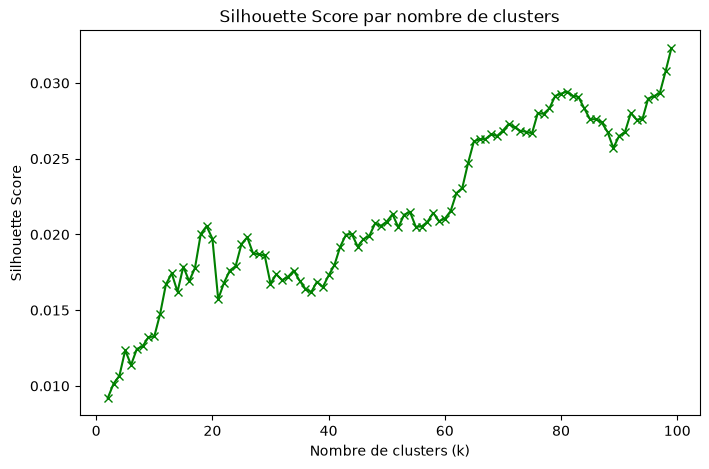

In [18]:
silhouette_scores = []
K2 = range(2, 100)

for k in K2:
    kmeanModel = KMeans(n_clusters=k, random_state=42).fit(X_reduced_final)
    score = silhouette_score(X, kmeanModel.labels_)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K2, silhouette_scores, 'gx-')
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title("Silhouette Score par nombre de clusters")
plt.show()

## Première conclusion

Grâce à notre vérifacation entre le nombre de components de TruncatedSVD et le nombre de clusters, on en vient à la conclusion que le meilleur assemblages est 10 components avec 10 clusters pour un score de 0.30411. 

On peut d'ailleurs vérifier ceci à l'aide de deux graphiques générés par une Elbow method et un silhouette score. Ils donnent chacun correlation sur 
ce résultat de 10 clusters.

Au delà de cela, on reconnait qu'avoir une dixaine de clusters ressemble à la réalité. Notre but est de grouper les symptomes, mais surtout de grouper les symptomes comme un médecin pourrait le faire. 

Or un médecin ne va pas faire 100/200 groupes de personnes qui serait absolument impossible à gérer facilement. 

La présence d'un pic entre 10 à 13 clusters de notre coefficient de silhouette va également dans notre sens, car le groupage des différents individus en une dixaine de groupe est cohérent avec ce qui peut se faire dans la réalité.

Nous décidons donc de partir sur ce nombre de clusters afin de regrouper nos symptômes de la manière la plus efficace et humaine possible.

## Clustering

On met donc notre nombre de cluster à 19, et on regroupe nos mots dans ceux-ci. 

On vérifie ensuite que nous obtenons un regroupement assez précis et adhéquat entre les éléments.

In [ ]:
k_final = 10

kmeans = KMeans(n_clusters=k_final, random_state=42, n_init="auto").fit(X_reduced_final)

centres_originaux = svd_final.inverse_transform(kmeans.cluster_centers_)

for k in range(k_final):
    indices = centres_originaux[k].argsort()[-10:][::-1]
    print(f"**** Cluster n°{k} ****")
    for l in indices:
        print(noms[l])
    print()

ValueError: shapes (10,2135) and (100,2135) not aligned: 2135 (dim 1) != 100 (dim 0)